# Bone Fracture Multi-Region X-ray — Final Research Notebook

## Two experiments
1. DenseNet201 baseline
2. DenseNet201 + CBAM

Binary classification:
- `not fractured`
- `fractured`

This version automatically discovers the Kaggle dataset path and checks for corrupted images before TensorFlow training.

**Important:** BFMRX is a multi-region dataset. Unless verified anatomical-region metadata is available, report results as multi-region fracture classification, not upper-limb-only classification.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4

INPUT_ROOT = Path("/kaggle/input")

# Automatically find the directory that directly contains train, val and test.
candidates = []

for p in INPUT_ROOT.rglob("*"):
    if not p.is_dir():
        continue
    try:
        child_dirs = {x.name.lower().strip() for x in p.iterdir() if x.is_dir()}
    except PermissionError:
        continue
    if {"train", "val", "test"}.issubset(child_dirs):
        candidates.append(p)

print("Candidate dataset directories:")
for p in candidates:
    print("  ", p)

if not candidates:
    raise FileNotFoundError(
        "Could not find a directory containing train, val and test."
    )

DATASET_DIR = candidates[0]

print("\nDataset root:", DATASET_DIR)
print("Exists:", DATASET_DIR.exists())

Candidate dataset directories:
   /kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification

Dataset root: /kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification
Exists: True


In [2]:
CLASS_NAMES = ["not fractured", "fractured"]

for split in ["train", "val", "test"]:
    split_path = DATASET_DIR / split
    print(f"\n{split}/")
    for class_dir in sorted(split_path.iterdir()):
        if class_dir.is_dir():
            print("   ", class_dir.name)

for split in ["train", "val", "test"]:
    for class_name in CLASS_NAMES:
        expected = DATASET_DIR / split / class_name
        if not expected.exists():
            raise FileNotFoundError(f"Missing expected class folder: {expected}")

print("\nDataset folder structure verified.")


train/
    fractured
    not fractured

val/
    fractured
    not fractured

test/
    fractured
    not fractured

Dataset folder structure verified.


## 3. Detect corrupted/unreadable images

The previous training run stopped because TensorFlow encountered a truncated JPEG. This version validates every image first.

Corrupted files are recorded and excluded explicitly rather than being silently ignored.

In [3]:
from PIL import Image

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def validate_images(folder):
    valid = []
    bad = []

    for path in Path(folder).rglob("*"):
        if not path.is_file() or path.suffix.lower() not in IMG_EXTS:
            continue

        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                img.load()

            valid.append(str(path))

        except Exception as e:
            bad.append({
                "file": str(path),
                "error": repr(e)
            })

    return valid, bad


split_paths = {
    "train": DATASET_DIR / "train",
    "val": DATASET_DIR / "val",
    "test": DATASET_DIR / "test"
}

valid_files = {}
bad_files = {}

for split_name, split_path in split_paths.items():
    valid_files[split_name] = []
    bad_files[split_name] = []

    for class_index, class_name in enumerate(CLASS_NAMES):
        class_dir = split_path / class_name
        valid, bad = validate_images(class_dir)

        for f in valid:
            valid_files[split_name].append((f, class_index))

        for item in bad:
            item["split"] = split_name
            item["class"] = class_name
            bad_files[split_name].append(item)

    print(
        f"{split_name:5s}: "
        f"{len(valid_files[split_name])} valid, "
        f"{len(bad_files[split_name])} corrupted/unreadable"
    )

train: 9240 valid, 6 corrupted/unreadable
val  : 823 valid, 6 corrupted/unreadable
test : 500 valid, 6 corrupted/unreadable


In [4]:
bad_rows = []

for split_name in bad_files:
    bad_rows.extend(bad_files[split_name])

bad_df = pd.DataFrame(
    bad_rows,
    columns=["file", "error", "split", "class"]
)

if len(bad_df) == 0:
    print("No corrupted/unreadable images found.")
else:
    print(f"Total corrupted/unreadable images: {len(bad_df)}")
    display(bad_df)

bad_df.to_csv(
    "/kaggle/working/corrupted_images_report.csv",
    index=False
)

print("Report saved to /kaggle/working/corrupted_images_report.csv")

Total corrupted/unreadable images: 18


,file,error,split,class
0,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (40 bytes not...,train,not fractured
1,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (14 bytes not...,train,not fractured
2,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (1 bytes not ...,train,not fractured
3,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (33 bytes not...,train,not fractured
4,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (10 bytes not...,train,not fractured
5,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (40 bytes not...,train,not fractured
6,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (40 bytes not...,val,not fractured
7,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (14 bytes not...,val,not fractured
8,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (1 bytes not ...,val,not fractured
9,/kaggle/input/datasets/bmadushanirodrigo/fract...,OSError('image file is truncated (33 bytes not...,val,not fractured


Report saved to /kaggle/working/corrupted_images_report.csv


In [5]:
count_rows = []

for split_name in ["train", "val", "test"]:
    for class_index, class_name in enumerate(CLASS_NAMES):
        n = sum(
            1 for _, label in valid_files[split_name]
            if label == class_index
        )
        count_rows.append({
            "split": split_name,
            "class": class_name,
            "valid_images_used": n
        })

counts_df = pd.DataFrame(count_rows)

display(counts_df)

display(
    counts_df.pivot(
        index="class",
        columns="split",
        values="valid_images_used"
    ).fillna(0).astype(int)
)

,split,class,valid_images_used
0,train,not fractured,4634
1,train,fractured,4606
2,val,not fractured,486
3,val,fractured,337
4,test,not fractured,262
5,test,fractured,238


split,test,train,val
class,,,
fractured,238,4606,337
not fractured,262,4634,486


In [6]:
for split_name in ["train", "val", "test"]:
    temp = counts_df[counts_df["split"] == split_name]
    total = int(temp["valid_images_used"].sum())

    print(f"\n{split_name.upper()} — {total} valid images")

    for _, row in temp.iterrows():
        pct = 100 * row["valid_images_used"] / total if total else 0
        print(
            f"  {row['class']:15s}: "
            f"{int(row['valid_images_used']):5d} ({pct:.2f}%)"
        )


TRAIN — 9240 valid images
  not fractured  :  4634 (50.15%)
  fractured      :  4606 (49.85%)

VAL — 823 valid images
  not fractured  :   486 (59.05%)
  fractured      :   337 (40.95%)

TEST — 500 valid images
  not fractured  :   262 (52.40%)
  fractured      :   238 (47.60%)


In [7]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.applications.densenet import preprocess_input

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

if not tf.config.list_physical_devices("GPU"):
    print("WARNING: GPU not detected. Enable a Kaggle GPU session.")

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 8. Build TensorFlow datasets from validated files

We do not use `image_dataset_from_directory` here. The validated file list prevents the known corrupted JPEGs from reaching the training pipeline.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.float32)


def make_dataset(file_list, training=False):
    paths = [item[0] for item in file_list]
    labels = [item[1] for item in file_list]

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(valid_files["train"], training=True)
val_ds = make_dataset(valid_files["val"], training=False)
test_ds = make_dataset(valid_files["test"], training=False)

print("TensorFlow datasets created successfully.")

I0000 00:00:1787767277.315069      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787767277.318043      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TensorFlow datasets created successfully.


In [9]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomTranslation(0.03, 0.03),
], name="augmentation")

def prepare_train(x, y):
    x = augmentation(x, training=True)
    x = preprocess_input(x)
    return x, y

def prepare_eval(x, y):
    x = preprocess_input(x)
    return x, y

train_ds_p = train_ds.map(
    prepare_train,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds_p = val_ds.map(
    prepare_eval,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds_p = test_ds.map(
    prepare_eval,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


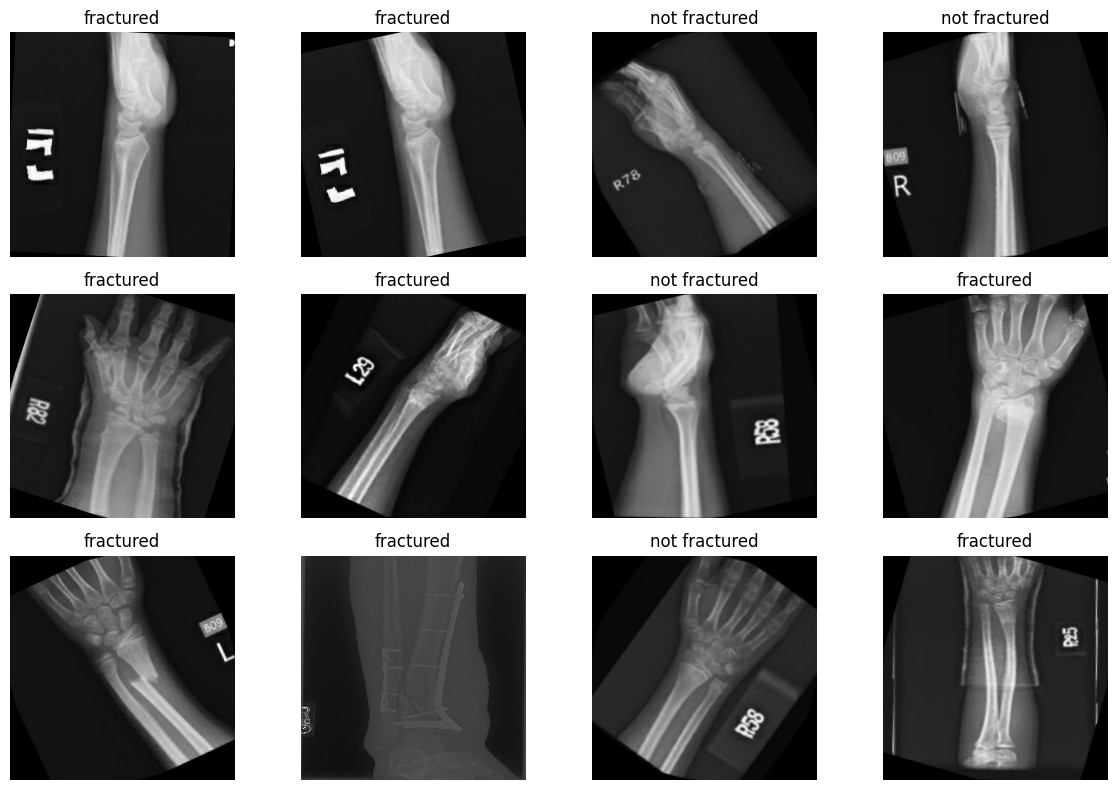

In [10]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = int(labels[i].numpy())
        plt.title(CLASS_NAMES[label_idx])
        plt.axis("off")

plt.tight_layout()
plt.show()

# Experiment 1 — DenseNet201 Baseline

Frozen ImageNet-pretrained DenseNet201 + global average pooling + dropout + binary sigmoid classifier.

In [11]:
def build_densenet201():
    base = DenseNet201(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base.trainable = False

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="xray"
    )

    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="fracture_probability"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="DenseNet201_Baseline"
    )


baseline = build_densenet201()

baseline.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

baseline.summary()

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "DenseNet201_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fracture_probability (Dense)    │ (None, 1)              │         1,921 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,323,905 (69.90 MB)

 Trainable params: 1,921 (7.50 KB)

 Non-trainable params: 18,321,984 (69.89 MB)

In [12]:
baseline_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/DenseNet201_Baseline_Best.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_baseline = baseline.fit(
    train_ds_p,
    validation_data=val_ds_p,
    epochs=EPOCHS,
    callbacks=baseline_callbacks
)

Epoch 1/20
  1/289 ━━━━━━━━━━━━━━━━━━━━ 4:03:23 51s/step - accuracy: 0.6562 - auc: 0.5575 - loss: 0.7758 - precision: 1.0000 - recall: 0.2143

I0000 00:00:1787767336.754768     133 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.5337 - auc: 0.5559 - loss: 0.7475 - precision: 0.5360 - recall: 0.4366
Epoch 1: val_auc improved from None to 0.76281, saving model to /kaggle/working/DenseNet201_Baseline_Best.keras

Epoch 1: finished saving model to /kaggle/working/DenseNet201_Baseline_Best.keras
289/289 ━━━━━━━━━━━━━━━━━━━━ 190s 482ms/step - accuracy: 0.5637 - auc: 0.5916 - loss: 0.7103 - precision: 0.5674 - recall: 0.5252 - val_accuracy: 0.6914 - val_auc: 0.7628 - val_loss: 0.6047 - val_precision: 0.5963 - val_recall: 0.7626 - learning_rate: 1.0000e-04
Epoch 2/20
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.6524 - auc: 0.7076 - loss: 0.6257 - precision: 0.6488 - recall: 0.6618
Epoch 2: val_auc improved from 0.76281 to 0.85448, saving model to /kaggle/working/DenseNet201_Baseline_Best.keras

Epoch 2: finished saving model to /kaggle/working/DenseNet201_Baseline_Best.keras
289/289 ━━━━━━━━━━━━━━━━━━━━ 67s 230ms/step - accuracy: 0.6673 - auc: 0.7297 

## 11. Evaluation utilities

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

def evaluate_binary_model(model, dataset, title):
    y_true = []
    y_prob = []

    for x, y in dataset:
        probabilities = model.predict(x, verbose=0).ravel()
        y_prob.extend(probabilities)
        y_true.extend(y.numpy().ravel())

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    metrics = {
        "Model": title,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Sensitivity/Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

    return metrics, y_true, y_prob, y_pred

               precision    recall  f1-score   support

not fractured       0.85      0.79      0.82       262
    fractured       0.79      0.84      0.81       238

     accuracy                           0.82       500
    macro avg       0.82      0.82      0.82       500
 weighted avg       0.82      0.82      0.82       500



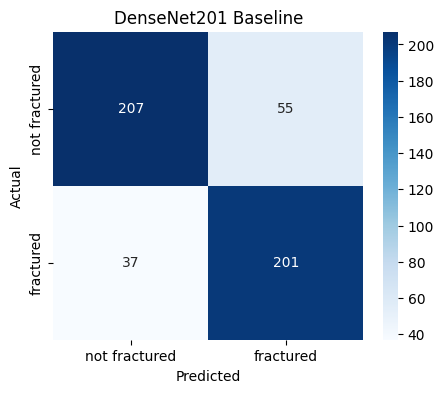

,Model,Accuracy,Precision,Sensitivity/Recall,Specificity,F1,ROC-AUC
0,DenseNet201 Baseline,0.816,0.785156,0.844538,0.790076,0.813765,0.890708


In [14]:
baseline_metrics, y_true_baseline, y_prob_baseline, y_pred_baseline = (
    evaluate_binary_model(
        baseline,
        test_ds_p,
        "DenseNet201 Baseline"
    )
)

display(pd.DataFrame([baseline_metrics]))

# Experiment 2 — DenseNet201 + CBAM

CBAM is the single proposed architectural improvement:
1. Channel attention
2. Spatial attention

In [15]:
class CBAM(layers.Layer):
    def __init__(
        self,
        reduction_ratio=16,
        kernel_size=7,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio
        self.kernel_size = kernel_size

    def build(self, input_shape):
        channels = int(input_shape[-1])
        hidden = max(channels // self.reduction_ratio, 1)

        self.channel_mlp_1 = layers.Dense(
            hidden,
            activation="relu"
        )

        self.channel_mlp_2 = layers.Dense(channels)

        self.spatial_conv = layers.Conv2D(
            filters=1,
            kernel_size=self.kernel_size,
            padding="same",
            activation="sigmoid"
        )

        super().build(input_shape)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(
            inputs,
            axis=[1, 2],
            keepdims=True
        )

        max_pool = tf.reduce_max(
            inputs,
            axis=[1, 2],
            keepdims=True
        )

        avg_attention = self.channel_mlp_2(
            self.channel_mlp_1(avg_pool)
        )

        max_attention = self.channel_mlp_2(
            self.channel_mlp_1(max_pool)
        )

        channel_attention = tf.nn.sigmoid(
            avg_attention + max_attention
        )

        x = inputs * channel_attention

        avg_spatial = tf.reduce_mean(
            x,
            axis=-1,
            keepdims=True
        )

        max_spatial = tf.reduce_max(
            x,
            axis=-1,
            keepdims=True
        )

        spatial_input = tf.concat(
            [avg_spatial, max_spatial],
            axis=-1
        )

        spatial_attention = self.spatial_conv(
            spatial_input
        )

        return x * spatial_attention

In [16]:
def build_densenet201_cbam():
    base = DenseNet201(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base.trainable = False

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="xray"
    )

    x = base(inputs, training=False)
    x = CBAM(name="CBAM")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="fracture_probability"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="DenseNet201_CBAM"
    )


cbam_model = build_densenet201_cbam()

cbam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

cbam_model.summary()

Model: "DenseNet201_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CBAM (CBAM)                     │ (None, 7, 7, 1920)     │       462,939 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fracture_probability (Dense)    │ (None, 1)              │         1,921 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,786,844 (71.67 MB)

 Trainable params: 464,860 (1.77 MB)

 Non-trainable params: 18,321,984 (69.89 MB)

In [17]:
cbam_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/DenseNet201_CBAM_Best.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_cbam = cbam_model.fit(
    train_ds_p,
    validation_data=val_ds_p,
    epochs=EPOCHS,
    callbacks=cbam_callbacks
)

Epoch 1/20
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.6650 - auc: 0.7313 - loss: 0.6050 - precision: 0.6705 - recall: 0.6455
Epoch 1: val_auc improved from None to 0.94095, saving model to /kaggle/working/DenseNet201_CBAM_Best.keras

Epoch 1: finished saving model to /kaggle/working/DenseNet201_CBAM_Best.keras
289/289 ━━━━━━━━━━━━━━━━━━━━ 175s 451ms/step - accuracy: 0.7626 - auc: 0.8532 - loss: 0.5033 - precision: 0.7710 - recall: 0.7449 - val_accuracy: 0.8542 - val_auc: 0.9410 - val_loss: 0.3275 - val_precision: 0.8145 - val_recall: 0.8338 - learning_rate: 1.0000e-04
Epoch 2/20
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.9030 - auc: 0.9636 - loss: 0.2738 - precision: 0.9023 - recall: 0.9000
Epoch 2: val_auc improved from 0.94095 to 0.96776, saving model to /kaggle/working/DenseNet201_CBAM_Best.keras

Epoch 2: finished saving model to /kaggle/working/DenseNet201_CBAM_Best.keras
289/289 ━━━━━━━━━━━━━━━━━━━━ 67s 231ms/step - accuracy: 0.9135 - auc: 0.9719 - los

               precision    recall  f1-score   support

not fractured       0.98      0.96      0.97       262
    fractured       0.95      0.98      0.97       238

     accuracy                           0.97       500
    macro avg       0.97      0.97      0.97       500
 weighted avg       0.97      0.97      0.97       500



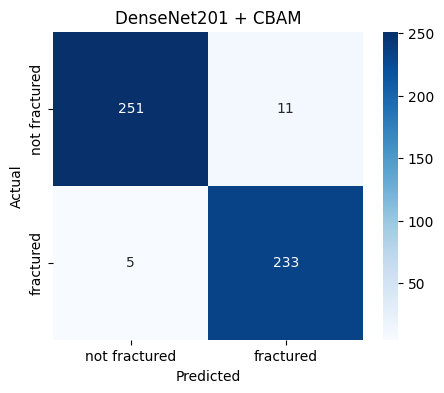

,Model,Accuracy,Precision,Sensitivity/Recall,Specificity,F1,ROC-AUC
0,DenseNet201 + CBAM,0.968,0.954918,0.978992,0.958015,0.966805,0.992286


In [18]:
cbam_metrics, y_true_cbam, y_prob_cbam, y_pred_cbam = (
    evaluate_binary_model(
        cbam_model,
        test_ds_p,
        "DenseNet201 + CBAM"
    )
)

display(pd.DataFrame([cbam_metrics]))

## 12. Final comparison with the published reference

In [19]:
published = {
    "Model": "Published DenseNet201",
    "Accuracy": 0.9735,
    "Precision": np.nan,
    "Sensitivity/Recall": 0.9778,
    "Specificity": 0.9706,
    "F1": 0.9741,
    "ROC-AUC": 0.99
}

comparison = pd.DataFrame([
    published,
    baseline_metrics,
    cbam_metrics
])

display(comparison)

comparison.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

,Model,Accuracy,Precision,Sensitivity/Recall,Specificity,F1,ROC-AUC
0,Published DenseNet201,0.9735,NaN,0.977800,0.970600,0.974100,0.990000
1,DenseNet201 Baseline,0.8160,0.785156,0.844538,0.790076,0.813765,0.890708
2,DenseNet201 + CBAM,0.9680,0.954918,0.978992,0.958015,0.966805,0.992286


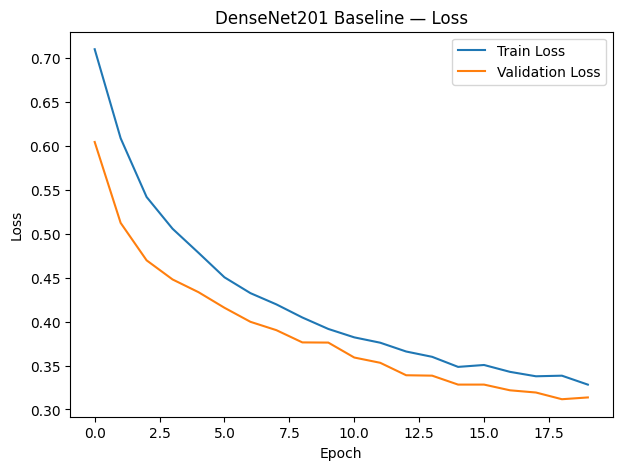

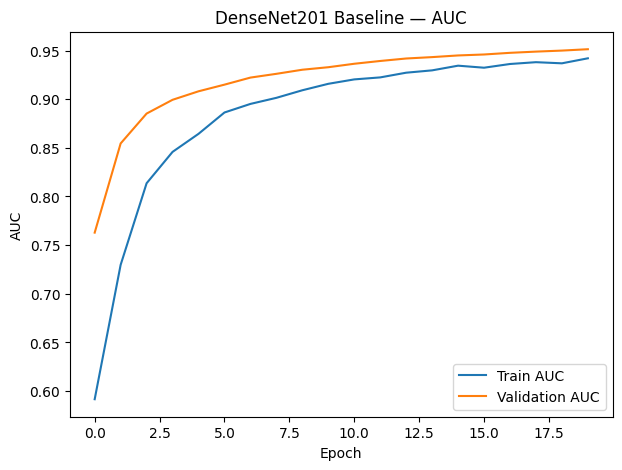

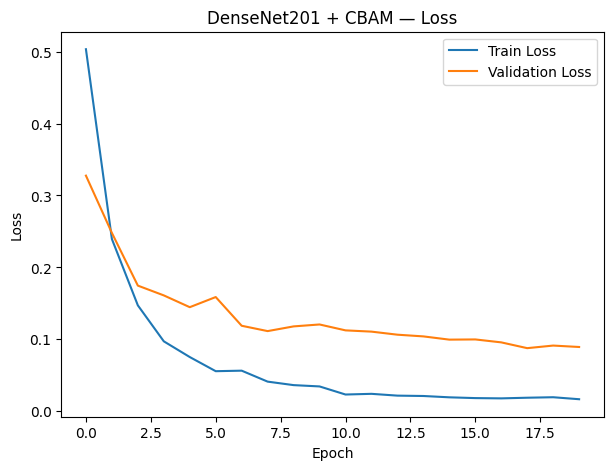

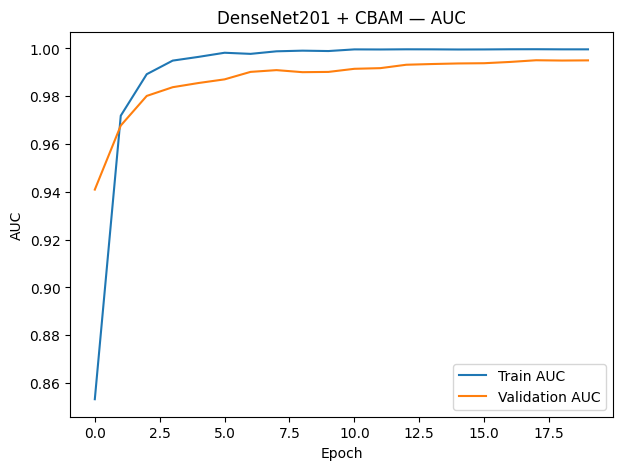

In [20]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)

    plt.figure(figsize=(7, 5))
    plt.plot(hist["loss"], label="Train Loss")
    plt.plot(hist["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title + " — Loss")
    plt.legend()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(hist["auc"], label="Train AUC")
    plt.plot(hist["val_auc"], label="Validation AUC")
    plt.xlabel("Epoch")
    plt.ylabel("AUC")
    plt.title(title + " — AUC")
    plt.legend()
    plt.show()

plot_history(history_baseline, "DenseNet201 Baseline")
plot_history(history_cbam, "DenseNet201 + CBAM")

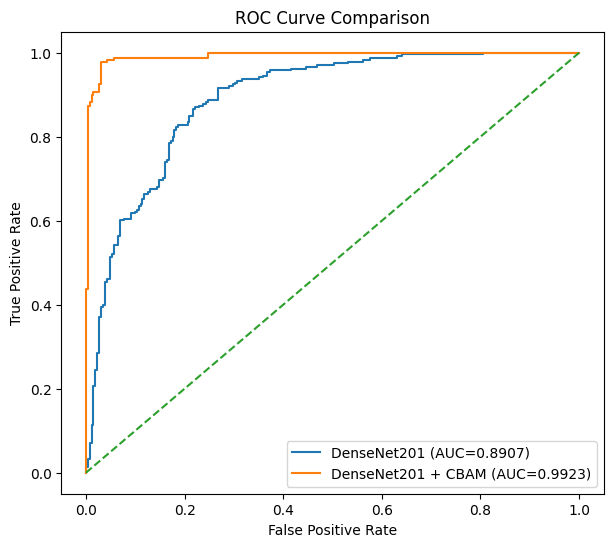

In [21]:
plt.figure(figsize=(7, 6))

fpr1, tpr1, _ = roc_curve(
    y_true_baseline,
    y_prob_baseline
)
auc1 = roc_auc_score(
    y_true_baseline,
    y_prob_baseline
)

fpr2, tpr2, _ = roc_curve(
    y_true_cbam,
    y_prob_cbam
)
auc2 = roc_auc_score(
    y_true_cbam,
    y_prob_cbam
)

plt.plot(
    fpr1,
    tpr1,
    label=f"DenseNet201 (AUC={auc1:.4f})"
)

plt.plot(
    fpr2,
    tpr2,
    label=f"DenseNet201 + CBAM (AUC={auc2:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [22]:
baseline.save(
    "/kaggle/working/DenseNet201_Baseline_Final.keras"
)

cbam_model.save(
    "/kaggle/working/DenseNet201_CBAM_Final.keras"
)

print("Saved:")
print(" - DenseNet201_Baseline_Final.keras")
print(" - DenseNet201_CBAM_Final.keras")
print(" - model_comparison.csv")
print(" - corrupted_images_report.csv")

Saved:
 - DenseNet201_Baseline_Final.keras
 - DenseNet201_CBAM_Final.keras
 - model_comparison.csv
 - corrupted_images_report.csv


# Final research reporting

### Experiment 1
DenseNet201 baseline.

### Experiment 2
DenseNet201 + CBAM.

Report for both:
- Accuracy
- Precision
- Sensitivity/Recall
- Specificity
- F1-score
- ROC-AUC
- Confusion matrix

### Research question

> Does adding CBAM to DenseNet201 improve fracture classification performance compared with the DenseNet201 baseline under the same dataset and evaluation protocol?

### Data-quality note

If corrupted/unreadable images are detected, report their number and state that they were excluded before training. The notebook creates `corrupted_images_report.csv`.

### Dataset limitation

The available BFMRX folder structure contains binary fracture labels but does not itself establish an upper-limb-only subset. Unless anatomical-region metadata is verified and used for filtering, describe the results as **multi-region bone fracture classification**.